# Retail Orders Analysis (Python + SQL)

End-to-end analysis of about 10,000 retail order lines from 2022 and 2023.

**Flow** (same as Ankit Bansal's tutorial, then extended):
1. Read the raw Kaggle file and clean it with pandas
2. Load the clean table into SQLite
3. Answer the business questions in SQL (`sql/analysis.sql`)
4. Extra analysis with window functions, then KPIs and charts

Dataset: Kaggle *Retail Orders* (`ankitbansal06/retail-orders`), saved as `data/raw/orders.csv`.

In [1]:
import sqlite3
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

sys.path.append("../src")
import pipeline

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

RAW = Path("../data/raw/orders.csv")
DB = Path("../data/retail_orders.db")

## 1. Read the raw file

Missing ship modes are written as the words `Not Available` and `unknown`.
If we read the file normally, pandas treats them as real ship modes.

In [2]:
raw_default = pd.read_csv(RAW)
raw_default["Ship Mode"].value_counts(dropna=False)

Ship Mode
Standard Class    5962
Second Class      1945
First Class       1538
Same Day           543
Not Available        4
unknown              1
NaN                  1
Name: count, dtype: int64

Reading with `na_values` turns them into proper missing values (NaN):

In [3]:
df = pd.read_csv(RAW, na_values=["Not Available", "unknown"])
print(df.shape)
print(df["Ship Mode"].value_counts(dropna=False))
df.head()

(9994, 16)
Ship Mode
Standard Class    5962
Second Class      1945
First Class       1538
Same Day           543
NaN                  6
Name: count, dtype: int64


,Order Id,Order Date,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub Category,Product Id,cost price,List Price,Quantity,Discount Percent
0,1,2023-03-01,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,FUR-BO-10001798,240,260,2,2
1,2,2023-08-15,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,FUR-CH-10000454,600,730,3,3
2,3,2023-01-10,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,OFF-LA-10000240,10,10,2,5
3,4,2022-06-18,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,FUR-TA-10000577,780,960,5,2
4,5,2022-07-13,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,OFF-ST-10000760,20,20,2,5


## 2. Rename columns to snake_case

The raw headers mix cases and contain spaces (`cost price`, `Order Id`). snake_case names are easier to type in pandas and SQL.

In [4]:
print("Before:", list(df.columns))
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
print("After: ", list(df.columns))

Before: ['Order Id', 'Order Date', 'Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Category', 'Sub Category', 'Product Id', 'cost price', 'List Price', 'Quantity', 'Discount Percent']
After:  ['order_id', 'order_date', 'ship_mode', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'category', 'sub_category', 'product_id', 'cost_price', 'list_price', 'quantity', 'discount_percent']


## 3. Derive discount, sale price and profit

The file only has `list_price`, `cost_price` and `discount_percent`. `list_price` is the line total before discount.

- `discount = list_price * discount_percent / 100`
- `sale_price = list_price - discount`
- `profit = sale_price - cost_price`

In [5]:
df["discount"] = df["list_price"] * df["discount_percent"] * 0.01
df["sale_price"] = df["list_price"] - df["discount"]
df["profit"] = df["sale_price"] - df["cost_price"]
df[["list_price", "discount_percent", "discount", "sale_price", "cost_price", "profit"]].head()

,list_price,discount_percent,discount,sale_price,cost_price,profit
0,260,2,5.2,254.8,240,14.8
1,730,3,21.9,708.1,600,108.1
2,10,5,0.5,9.5,10,-0.5
3,960,2,19.2,940.8,780,160.8
4,20,5,1.0,19.0,20,-1.0


## 4. Convert `order_date` from text to a date

In [6]:
print("Before:", df["order_date"].dtype)
df["order_date"] = pd.to_datetime(df["order_date"], format="%Y-%m-%d")
print("After: ", df["order_date"].dtype)
print("Range: ", df["order_date"].min().date(), "to", df["order_date"].max().date())

Before: object
After:  datetime64[ns]
Range:  2022-01-01 to 2023-12-31


## 5. Drop columns we no longer need

`list_price` and `cost_price` are now captured in `sale_price`, `discount` and `profit`.
The tutorial also dropped `discount_percent`. I keep it because the discount analysis (Q11) uses it.

In [7]:
df = df.drop(columns=["list_price", "cost_price"])
print(df.shape)
df.dtypes

(9994, 17)


order_id                     int64
order_date          datetime64[ns]
ship_mode                   object
segment                     object
country                     object
city                        object
state                       object
postal_code                  int64
region                      object
category                    object
sub_category                object
product_id                  object
quantity                     int64
discount_percent             int64
discount                   float64
sale_price                 float64
profit                     float64
dtype: object

## 6. Checks after cleaning

In [8]:
checks = pd.DataFrame({
    "check": ["rows", "columns", "duplicate order_id", "missing values (all columns)",
              "missing ship_mode", "negative profit lines", "zero-value lines (sale_price = 0)"],
    "before (raw)": [len(raw_default), raw_default.shape[1], raw_default["Order Id"].duplicated().sum(),
                     raw_default.isna().sum().sum(), raw_default["Ship Mode"].isna().sum(), "n/a", "n/a"],
    "after (clean)": [len(df), df.shape[1], df["order_id"].duplicated().sum(),
                      df.isna().sum().sum(), df["ship_mode"].isna().sum(),
                      (df["profit"] < 0).sum(), (df["sale_price"] == 0).sum()],
})
checks

,check,before (raw),after (clean)
0,rows,9994,9994
1,columns,16,17
2,duplicate order_id,0,0
3,missing values (all columns),1,6
4,missing ship_mode,1,6
5,negative profit lines,n/a,3997
6,zero-value lines (sale_price = 0),n/a,507


Notes:
- No rows are lost and every `order_id` is unique, so each row is one order.
- The 6 missing ship modes are kept, because the rows still have valid sales and profit.
- 507 lines have a list price and cost of 0 (small items rounded down in the source file). They add nothing to sales or profit, so they are kept.
- 3,997 lines (40%) have negative profit. The next cell shows why.

In [9]:
loss = df[df["profit"] < 0]
# list_price and cost_price were dropped, so rebuild them from the derived columns
list_price = loss["sale_price"] + loss["discount"]
cost_price = loss["sale_price"] - loss["profit"]
print("Loss-making lines:          ", len(loss))
print("...of which list = cost:    ", (list_price == cost_price).sum())
print("Total loss on these lines:  ", round(loss["profit"].sum(), 1))
print("As % of total profit:       ", round(100 * -loss["profit"].sum() / df["profit"].sum(), 2))

Loss-making lines:           3997
...of which list = cost:     3955
Total loss on these lines:   -3150.6
As % of total profit:        1.54


Almost every loss-making line is an item whose list price equals its cost price (no markup), so any discount pushes it below zero.
The losses are small in total, but they show that discounting zero-margin items only gives money away.

The same cleaning lives in `src/pipeline.py`. This check confirms both give the same table:

In [10]:
pd.testing.assert_frame_equal(df, pipeline.clean(pipeline.load_raw(RAW)))
print("Notebook cleaning matches src/pipeline.py")

Notebook cleaning matches src/pipeline.py


## 7. Load into SQLite

The tutorial loaded into SQL Server. SQLite needs no server, so anyone can rerun the project. Dates are stored as `YYYY-MM-DD` text so SQLite's `strftime()` can read them.

In [11]:
pipeline.load_to_sqlite(df, DB)
conn = sqlite3.connect(DB)
pd.read_sql_query("SELECT COUNT(*) AS rows_loaded, MIN(order_date) AS first_date, MAX(order_date) AS last_date FROM df_orders", conn)

,rows_loaded,first_date,last_date
0,9994,2022-01-01,2023-12-31


## 8. SQL analysis

All queries live in `sql/analysis.sql`. Each one starts with a `-- name:` line, so here we read the file and run the queries one at a time.

In [12]:
queries = pipeline.read_queries("../sql/analysis.sql")

def run(name):
    print(queries[name].splitlines()[0])   # the comment line with the question
    return pd.read_sql_query(queries[name], conn)

list(queries)

['q1_top10_revenue_products',
 'q2_top5_products_per_region',
 'q3_mom_sales_2022_vs_2023',
 'q4_best_month_per_category',
 'q5_subcategory_profit_growth',
 'q6_running_total_sales',
 'q7_category_revenue_share',
 'q8_subcategory_rank_within_category',
 'q9_region_profitability',
 'q10_segment_profitability',
 'q11_discount_impact']

### Q1. Top 10 products by revenue

In [13]:
run("q1_top10_revenue_products")

-- Q1. Top 10 products by revenue.


,product_id,sales
0,TEC-CO-10004722,59514.0
1,OFF-BI-10003527,26525.3
2,TEC-MA-10002412,21734.4
3,FUR-CH-10002024,21096.2
4,OFF-BI-10001359,19090.2
5,OFF-BI-10000545,18249.0
6,TEC-CO-10001449,18151.2
7,TEC-MA-10001127,17906.4
8,OFF-BI-10004995,17354.8
9,OFF-SU-10000151,16325.8


### Q2. Top 5 products in each region

In [14]:
run("q2_top5_products_per_region")

-- Q2. Top 5 products by revenue in each region.


,region,rank_in_region,product_id,sales
0,Central,1,TEC-CO-10004722,16975.0
1,Central,2,TEC-MA-10000822,13770.0
2,Central,3,OFF-BI-10001120,11056.5
3,Central,4,OFF-BI-10000545,10132.7
4,Central,5,OFF-BI-10004995,8416.1
5,East,1,TEC-CO-10004722,29099.0
6,East,2,TEC-MA-10001047,13767.0
7,East,3,FUR-BO-10004834,11274.1
8,East,4,OFF-BI-10001359,8463.6
9,East,5,TEC-CO-10001449,8316.0


### Q3. Month-over-month sales, 2022 vs 2023

In [15]:
run("q3_mom_sales_2022_vs_2023")

-- Q3. Month-over-month sales, 2022 vs 2023.


,order_month,sales_2022,sales_2023,growth_pct
0,1,94712.5,88632.6,-6.42
1,2,90091.0,128124.2,42.22
2,3,80106.0,82512.3,3.00
3,4,95451.6,111568.6,16.88
4,5,79448.3,86447.9,8.81
5,6,94170.5,68976.5,-26.75
6,7,78652.2,90563.8,15.14
7,8,104808.0,87733.6,-16.29
8,9,79142.2,76658.6,-3.14
9,10,118912.7,121061.5,1.81


### Q4. Highest-sales month for each category

In [16]:
run("q4_best_month_per_category")

-- Q4. For each category, the month (year-month) with the highest sales.


,category,order_year_month,sales
0,Furniture,2022-10,42888.9
1,Office Supplies,2023-02,44118.5
2,Technology,2023-10,53000.1


### Q5. Sub-category with the highest profit growth, 2023 vs 2022

In [17]:
run("q5_subcategory_profit_growth")

-- Q5. Sub-categories by profit growth, 2023 vs 2022 (the first row answers the question).


,sub_category,profit_2022,profit_2023,profit_growth,growth_pct
0,Machines,7243.2,10878.5,3635.3,50.19
1,Phones,13024.7,15343.6,2318.9,17.80
2,Binders,8685.5,10523.1,1837.6,21.16
3,Storage,8907.4,10630.6,1723.2,19.35
4,Accessories,7387.2,8057.4,670.2,9.07
5,Supplies,1500.7,1937.4,436.7,29.10
6,Chairs,14725.3,15089.8,364.5,2.48
7,Envelopes,607.2,640.0,32.8,5.40
8,Art,924.1,935.7,11.6,1.26
9,Fasteners,40.1,8.8,-31.3,-78.05


### Q6 (extension). Year-to-date running total

In [18]:
run("q6_running_total_sales")

-- Q6. Monthly sales with a running total that restarts each year.


,order_year_month,sales,running_total_ytd
0,2022-01,94712.5,94712.5
1,2022-02,90091.0,184803.5
2,2022-03,80106.0,264909.5
3,2022-04,95451.6,360361.1
4,2022-05,79448.3,439809.4
5,2022-06,94170.5,533979.9
6,2022-07,78652.2,612632.1
7,2022-08,104808.0,717440.1
8,2022-09,79142.2,796582.3
9,2022-10,118912.7,915495.0


### Q7 (extension). Category share of revenue and profit

In [19]:
run("q7_category_revenue_share")

-- Q7. Each category's share of total revenue and profit.


,category,sales,sales_share_pct,profit,profit_share_pct
0,Technology,806873.5,36.41,76433.5,37.25
1,Furniture,715340.7,32.28,66480.7,32.40
2,Office Supplies,693644.5,31.30,62254.5,30.34


### Q8 (extension). Sub-categories ranked by profit within each category

In [20]:
run("q8_subcategory_rank_within_category")

-- Q8. Sub-categories ranked by profit inside their category.


,category,sub_category,sales,profit,margin_pct,profit_rank
0,Furniture,Chairs,316825.1,29815.1,9.41,1
1,Furniture,Tables,199361.2,18591.2,9.33,2
2,Furniture,Bookcases,110816.1,10496.1,9.47,3
3,Furniture,Furnishings,88338.3,7578.3,8.58,4
4,Office Supplies,Storage,215908.0,19538.0,9.05,1
5,Office Supplies,Binders,196038.6,19208.6,9.80,2
6,Office Supplies,Appliances,103697.7,10267.7,9.90,3
7,Office Supplies,Paper,75831.3,6001.3,7.91,4
8,Office Supplies,Supplies,45058.1,3438.1,7.63,5
9,Office Supplies,Art,26259.8,1859.8,7.08,6


### Q9 (extension). Regional profitability

In [21]:
run("q9_region_profitability")

-- Q9. Regional sales, profit and margin, with year-over-year sales growth.


,region,sales,profit,margin_pct,sales_growth_pct,profit_rank
0,West,699858.6,62558.6,8.94,-11.20,1
1,East,654320.0,58220.0,8.90,11.06,2
2,Central,483668.6,46378.6,9.59,13.09,3
3,South,378011.5,38011.5,10.06,1.17,4


### Q10 (extension). Segment profitability

In [22]:
run("q10_segment_profitability")

-- Q10. Customer segment sales, profit, margin and average order value.


,segment,orders,sales,profit,margin_pct,avg_order_value
0,Consumer,5191,1119696.0,101586.0,9.07,215.70
1,Corporate,3020,681657.7,65637.7,9.63,225.71
2,Home Office,1783,414505.0,37945.0,9.15,232.48


### Q11 (extension). Discount impact on profit

In [23]:
run("q11_discount_impact")

-- Q11. How the discount percentage relates to profit margin.


,discount_percent,order_lines,sales,discount_given,profit,margin_pct
0,2,2523,563500.0,11500.0,59380.0,10.54
1,3,2542,563482.7,17427.3,54992.7,9.76
2,4,2497,538560.0,22440.0,48820.0,9.06
3,5,2432,550316.0,28964.0,41976.0,7.63


## 9. KPIs

The pandas totals should match the SQL results above.

In [24]:
kpis = pipeline.compute_kpis(df)
pd.Series(kpis, name="value").to_frame()

,value
order_lines,9994
orders,9994
products,1862
date_from,2022-01-01
date_to,2023-12-31
total_sales,2215858.7
total_profit,205168.7
total_discount,80331.3
profit_margin_pct,9.26
avg_order_value,221.72


In [25]:
sql_totals = pd.read_sql_query("SELECT ROUND(SUM(sale_price), 2) AS sales, ROUND(SUM(profit), 2) AS profit FROM df_orders", conn)
assert sql_totals.loc[0, "sales"] == kpis["total_sales"]
assert sql_totals.loc[0, "profit"] == kpis["total_profit"]
print("SQL and pandas totals match:", sql_totals.to_dict("records")[0])

SQL and pandas totals match:

 {'sales': 2215858.7, 'profit': 205168.7}


## 10. Charts

The charts use navy as the main colour, steel blue for comparisons and amber to highlight each answer and are saved to `outputs/charts/`.

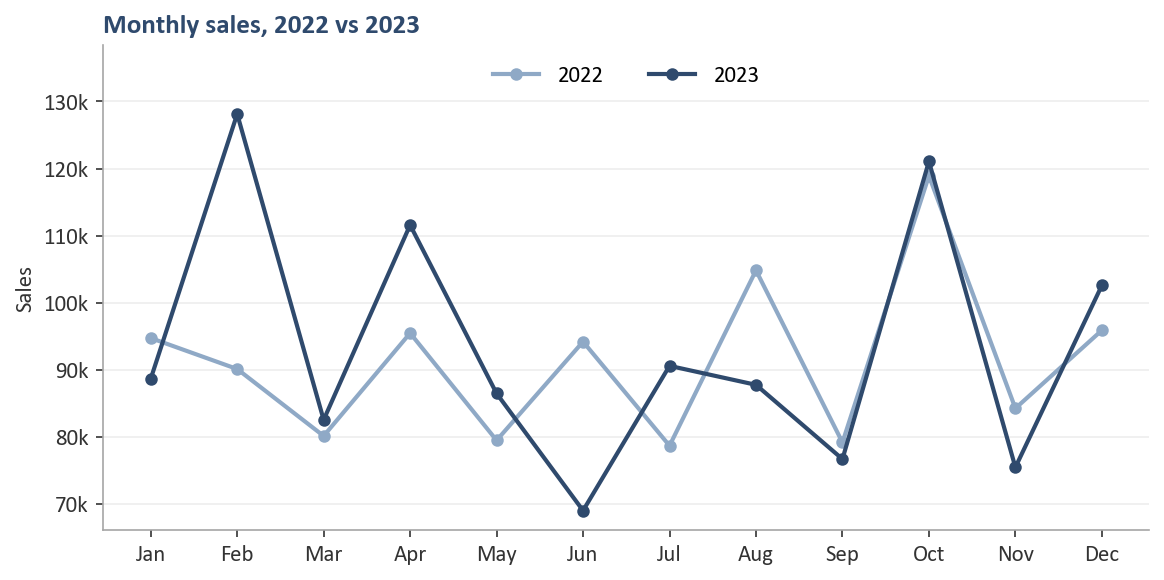

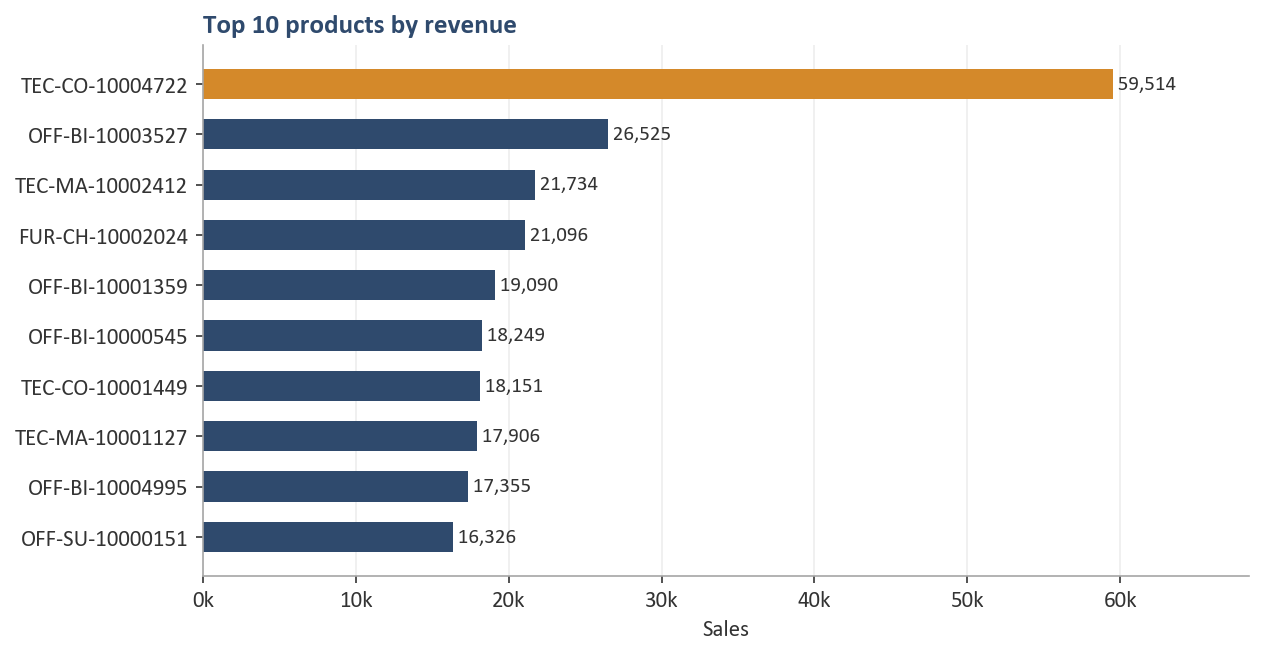

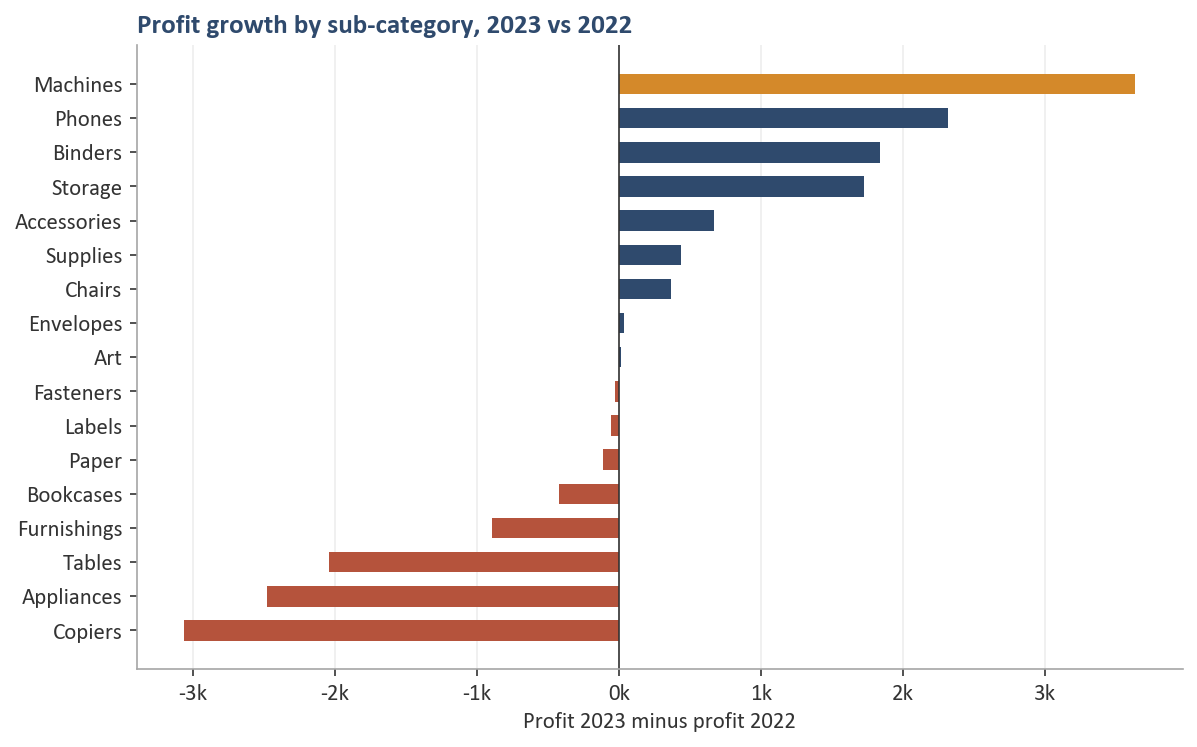

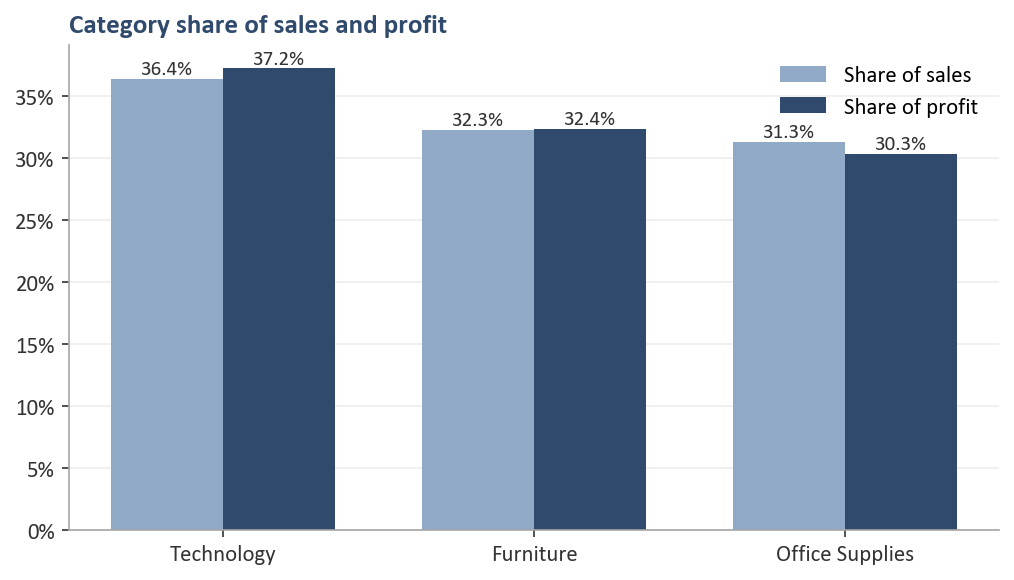

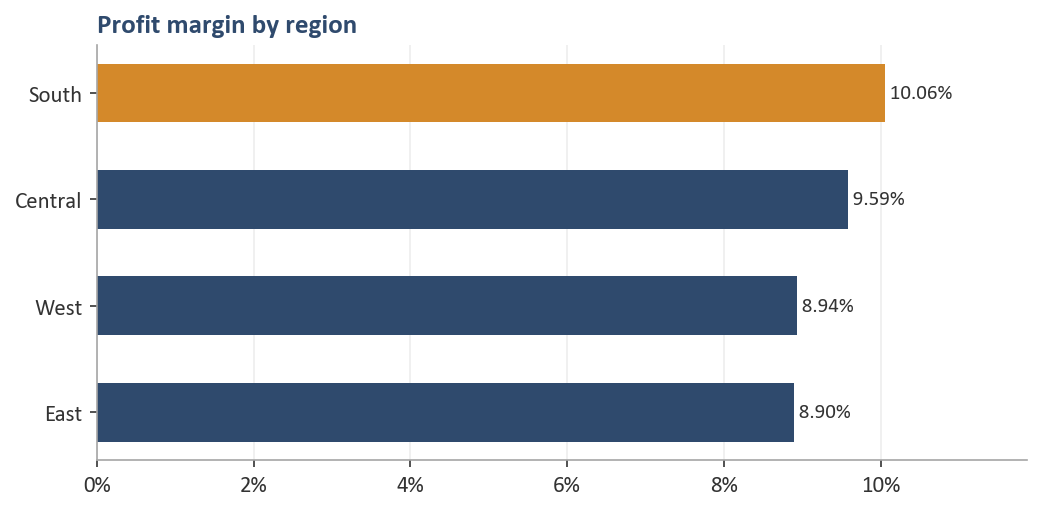

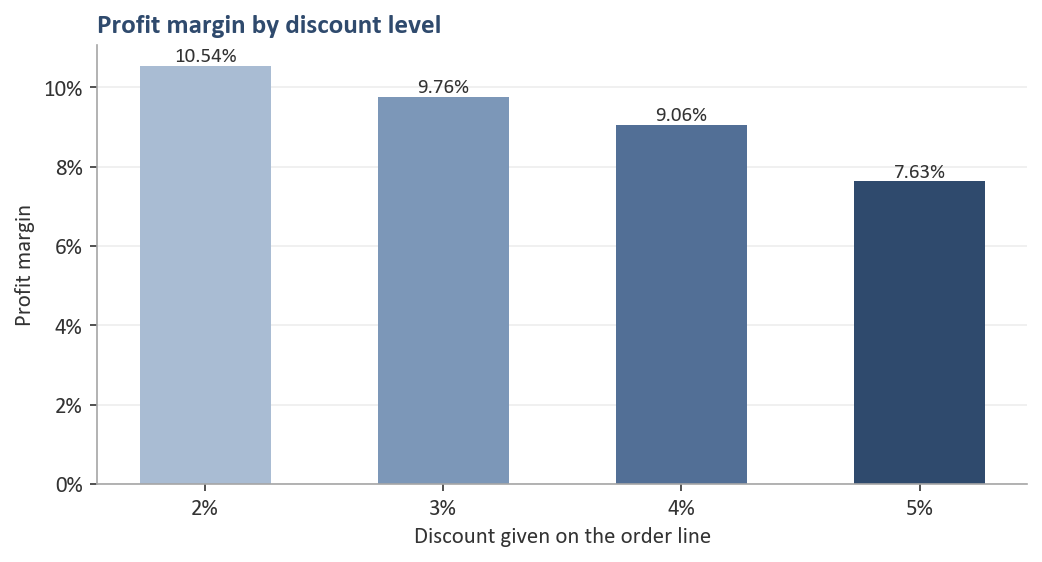

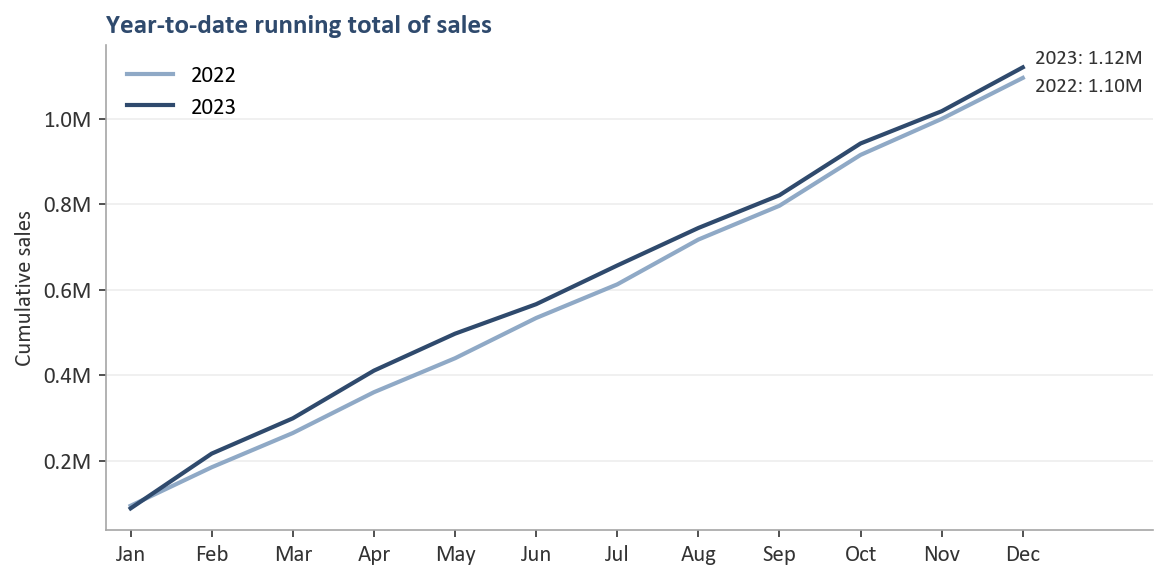

In [26]:
results = {name: pd.read_sql_query(q, conn) for name, q in queries.items()}
chart_dir = Path("../outputs/charts")
pipeline.make_charts(results, chart_dir)
for png in sorted(chart_dir.glob("*.png")):
    display(Image(filename=str(png), width=760))

In [27]:
conn.close()

## 11. Key findings

1. **Sales grew 2.25% in 2023** (1.096M to 1.120M) and profit grew 1.90%. The overall margin is 9.26%.
2. **One copier, `TEC-CO-10004722`, is the top product** with 59.5k in sales, more than twice the second product. It is also #1 in the Central, East and West regions.
3. **Monthly sales are uneven.** February 2023 was up 42% on February 2022, but June 2023 was down 27% on June 2022.
4. **Machines had the highest profit growth** (+3.6k, +50%). Copiers, Appliances and Tables lost the most profit.
5. **Technology is the biggest category** (36.4% of sales, 37.2% of profit). The three categories have similar margins.
6. **South has the best margin (10.06%) but the lowest sales.** West has the most sales but its sales fell 11.2% in 2023.
7. **Bigger discounts mean lower margins:** 10.54% at 2% discount down to 7.63% at 5%.
8. **40% of order lines lose money** because they have no markup and still get a discount. The loss is small (3.2k, 1.5% of profit), but it is easy to stop.